In [1]:
from hiepy.utils.dimtree import DimTree
import torch
from hiepy import randn, full, squeeze
from itertools import product
from scipy.special import binom
import numpy as np
from math import prod
import hiepy
torch.set_default_dtype(torch.double)

In [7]:
rel_err = torch.linalg.norm(prod_torch-prod_ht.full()) / torch.linalg.norm(prod_torch)
prod_ht = hiepy.ele_mul(x_ht,y_ht,opts={"max_rank":1})
prod_ht.rank

{(0, 1, 2): 1, (0,): 1, (1,): 1, (2,): 1, (0, 1): 1}

In [66]:
shape = 5,5,5,5,5,5,5,5
x = hiepy.hilbert(shape) + hiepy.ones(shape) + hiepy.randn(shape)
x,_ = hiepy.truncate_svd(x, {"atol":1e-8})
U0 = x.U[(0,)]
U1 = x.U[(1,)]
B01 = hiepy.matricize(x.B[(0,1)],t=[0,1])
U01 = torch.kron(U0,U1)@ B01
U23 = torch.kron(x.U[(2,)],x.U[(3,)])@hiepy.matricize(x.B[(2,3)],t=[0,1])
U0123 = torch.kron(U01.contiguous(),U23.contiguous())
U0123 = U0123 @ hiepy.matricize(x.B[(0,1,2,3)],t=[0,1])
test = U0123.T@U0123
test

tensor([[ 1.0000e+00, -8.8905e-17,  1.6487e-17,  9.5410e-18,  3.2960e-17,
          1.5613e-17,  1.9082e-17, -1.0408e-17],
        [-8.8905e-17,  1.0000e+00, -6.0986e-17,  5.7072e-16, -3.2092e-16,
          1.2837e-16, -2.8449e-16, -3.0045e-15],
        [ 1.6487e-17, -6.0986e-17,  1.0000e+00,  2.2484e-16, -2.2423e-16,
         -3.0222e-17, -1.1485e-15,  2.6249e-14],
        [ 9.5410e-18,  5.7072e-16,  2.2484e-16,  1.0000e+00,  5.6552e-16,
         -1.1935e-15, -2.0040e-14, -1.4728e-13],
        [ 3.2960e-17, -3.2092e-16, -2.2423e-16,  5.6552e-16,  1.0000e+00,
         -9.3252e-14, -1.0548e-12,  7.2047e-12],
        [ 1.5613e-17,  1.2837e-16, -3.0222e-17, -1.1935e-15, -9.3252e-14,
          1.0000e+00,  8.6681e-12,  1.0326e-09],
        [ 1.9082e-17, -2.8449e-16, -1.1485e-15, -2.0040e-14, -1.0548e-12,
          8.6681e-12,  1.0000e+00, -7.3430e-08],
        [-1.0408e-17, -3.0045e-15,  2.6249e-14, -1.4728e-13,  7.2047e-12,
          1.0326e-09, -7.3430e-08,  9.9999e-01]])

In [17]:
x_ = x[0]
print(x_.dtree)

  (0, 1)  
 (0,) (1,)


In [ ]:
x

In [11]:
torch.kron(torch.tensor([1,2,3]), torch.tensor([1,1,1]))

tensor([1, 1, 1, 2, 2, 2, 3, 3, 3])

In [23]:
import torch
import hiepy

gen = torch.Generator().manual_seed(42)
x = torch.randn(2,3,4,generator=gen)
x_ht = hiepy.to_htt(x, {"atol":1e-8})
t = (0,1)
hiepy.local_left_svd(x_ht)[t]


(tensor([[-1.0000e+00, -1.1928e-18,  2.1948e-17, -1.1690e-17],
         [ 1.1928e-18, -1.0000e+00,  2.7756e-16,  3.4694e-17],
         [-2.1948e-17, -4.4409e-16, -1.0000e+00, -5.2909e-17],
         [-1.1690e-17,  4.8572e-17, -5.2909e-17,  1.0000e+00]]),
 tensor([3.6357, 1.3479, 0.5663, 0.3282]))

In [3]:


max_nr_dims = 15
max_dim_sz = 6
max_iter_per_tuple = 5

counter = 0

broken = False
for nr_singleton_dims, nr_total_dims in product(range(1,max_nr_dims), range(1,max_nr_dims)):
    if nr_total_dims - nr_singleton_dims < 2:
        continue
    
    for _ in range(min(int(binom(nr_total_dims, nr_singleton_dims)),max_iter_per_tuple)):
        
        for nr_s_dims in range(1,nr_singleton_dims):
        
            # Sample basis shape
            shape = np.random.randint(low=2, high=max_dim_sz, size=nr_total_dims)
            
            # Sample singleton position
            s_idx = np.random.choice(a=nr_total_dims, size=nr_singleton_dims, replace=False)
            
            # Insert singleton dimensions
            shape[s_idx] = 1
            
            # Create ht tensor
            x_ht = randn(shape=tuple(shape),rank=5)
            
            # Unfold to torch
            x_t = x_ht.full()
            
            # Sample which singletom dimension are squeezed
            squeez_idx = np.random.choice(a=nr_singleton_dims, size=nr_s_dims,replace=False)
            squeez_dim = list(s_idx[squeez_idx])
            
            # Check 
            x_t_squeez = torch.squeeze(x_t,dim=squeez_dim)
            x_ht_squeez = squeeze(x_ht, dims=squeez_dim)
            assert torch.allclose(x_t_squeez, x_ht_squeez.full())

            
            


In [3]:
print(x.dtree)

    (0, 1, 2, 3)    
  (0, 1)    (2, 3)  
 (0,) (1,) (2,) (3,)


In [7]:
a = {1:2, 3:4}
del a[1]
a

{3: 4}

In [35]:
singleton_dims = range(1,5)
total_dims = range(1,15)
max_sz = 7
max_iter_per_tuple = 5
for s,d in tqdm(product(singleton_dims, total_dims)):
    if d-s < 2:
        continue
    for _ in range(min(10,int(binom(d,s)))):
        for sq in range(1,s):
            s_dims = np.random.choice(a=d,size=s,replace=False)
            shape = np.random.randint(2,max_sz,size=d)
            shape[s_dims] = 1
            
            x_ht = hiepy.randn(shape=tuple(shape), rank=5)
            x_t = x_ht.full()
            
            actual_squeezed = sorted(s_dims[np.random.choice(s,size=sq,replace=False)])
            x_t_sq = torch.squeeze(x_t,dim=actual_squeezed)
            x_ht_sq = hiepy.squeeze(x_ht,dims=actual_squeezed)
            
            if torch.allclose(x_t_sq,x_ht_sq.full()):
                print("WIN")

23it [00:00, 197.14it/s]

WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN


43it [00:03, 11.82it/s] 

WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN


52it [00:03, 14.25it/s]

WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN


56it [00:04, 13.81it/s]

WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN
WIN


In [3]:
hiepy.squeeze(x,dims=1).full()

tensor([[[-0.1576],
         [-0.1341],
         [ 0.4614]],

        [[ 0.1524],
         [ 0.1296],
         [-0.4460]]])

In [9]:
hiepy.local_left_svd(x)

{(0, 1, 2, 3): (tensor([[1.]]), tensor([10.2898])),
 (0,
  1): (tensor([[-1.0000e+00, -4.6649e-16,  1.2408e-15,  2.6661e-16, -1.1497e-16,
           -9.9790e-17, -2.2122e-16,  2.2302e-16,  3.6069e-18,  1.8635e-17],
          [ 4.6649e-16, -1.0000e+00,  1.1768e-14, -1.2768e-15, -4.4409e-16,
            6.9736e-16, -2.7756e-17, -5.8287e-16,  3.6429e-16,  1.0408e-16],
          [ 1.2408e-15,  1.1990e-14,  1.0000e+00, -2.2204e-16, -7.9103e-16,
            5.3776e-17,  2.7756e-17, -2.2204e-16,  7.6328e-17, -6.5919e-17],
          [ 2.6661e-16, -1.5266e-15,  3.6082e-16,  1.0000e+00,  1.1154e-15,
            3.0748e-16, -3.9899e-16, -2.7756e-17, -2.9490e-17,  2.3115e-16],
          [-1.1497e-16, -1.8041e-16,  7.9103e-16, -9.7838e-16,  1.0000e+00,
           -6.3079e-16, -1.9949e-16, -1.8908e-16, -4.7271e-17,  5.8330e-17],
          [-9.9790e-17,  3.3480e-16, -1.1449e-16, -2.7192e-16,  4.7857e-16,
            1.0000e+00, -2.4286e-15, -2.8927e-16,  1.5705e-16, -1.8044e-16],
          [ 2.2122e-

In [ ]:
"""Torch mode product module.

This module provides functionality to compute the multi-mode product (tensor contraction)
between a 2D linear transformation matrix and a PyTorch tensor along specified modes.
"""

def mode_mul_torch(A: torch.Tensor, x: torch.Tensor, modes: Sequence[int] | int) -> torch.Tensor:
    r"""
    Computes the mode product between a matrix A and a tensor x.

    This operation is equivalent to contracting the tensor $x$ along the specified
    hierarchical axes (modes) with the rows of the transformation matrix $A$.
    The mathematical operation maps to:
    
    $$y = x \times_{\mu_1, \dots, \mu_k} A$$

    where the targeted modes $\mu_i$ of $x$ are flattened to match the column 
    dimension of $A$.

    Parameters
    ----------
    A : torch.Tensor
        The 2D transformation matrix of shape $(J, \prod_{i=1}^k I_{\mu_i})$, 
        where $J$ is the new output dimension size and the second dimension matches 
        the product of the sizes of the contracted modes.
    x : torch.Tensor
        The input tensor of arbitrary dimensionality and shape $(I_0, I_1, \dots, I_{d-1})$.
    modes : Sequence[int] | int
        The mode index or sequence of mode indices along which the contraction 
        is performed. Negative indexing is supported.

    Returns
    -------
    torch.Tensor
        The resulting contracted tensor. The contracted dimensions are replaced by 
        a single new dimension of size $J$, placed at the position of the first 
        contracted mode.

    Raises
    ------
    ValueError
        If ``A`` is not a 2D tensor.
        If any mode index is out of bounds for the dimensionality of ``x``.
        If duplicate indices are detected within `modes`.
        If the combined size of the targeted modes does not match the column count of ``A``.

    Notes
    -----
    - Memory footprint is optimized: No physischal reshaping or permuting is applied 
      to the input tensor ``x``.

    Examples
    --------
import torch
x = torch.randn(2, 3, 4, 5)
# Contract modes 1 and 3 (sizes 3 and 5 -> combined size 15)
A = torch.randn(10, 15)
y = mode_mul_torch(A, x, modes=(1, 3))
y.shape
    torch.Size([2, 10, 4])
    """
    order = x.ndim

    # Input normalization
    raw_modes = (modes,) if isinstance(modes, int) else tuple(modes)
    
    # Resolve negative indices
    resolved_modes = tuple(mu + order if mu < 0 else mu for mu in raw_modes)
    
    # Check input validity
    if A.ndim != 2:
        raise ValueError(f"Argument 'A' must be a 2D matrix, but got shape {A.shape}")
    
    if not all(0 <= mu < order for mu in resolved_modes):
        raise ValueError(f"At least one mode in {raw_modes} is out of range for a tensor with ndim={order}"
        )
    
    if len(set(resolved_modes)) != len(resolved_modes):
        raise ValueError(f"Duplicate entries in modes are not allowed: {raw_modes}")
    
    # 3. Dimensionen berechnen (Nutzung von schnellem math.prod statt torch.prod)
    target_shape = tuple(x.shape[mu] for mu in resolved_modes)
    contraction_modes_sz = math.prod(target_shape)
    
    if contraction_modes_sz != A.shape[1]:
            raise ValueError(
                f"Dimension mismatch: The targeted modes of x have a combined size of {contraction_modes_sz}, "
                f"but A expects {A.shape[1]} columns."
                )
            
    # Virtually split column of A into target dimensions
    A_reshaped = A.reshape(-1, *target_shape)
    
    # Contraction
    A_dims = list(range(1, len(resolved_modes) + 1))
    prod = torch.tensordot(x, A_reshaped, dims=(resolved_modes, A_dims))  # type: ignore
    
    # Move the newly introduced dimension to the correct target position
    actual_destination = sum(1 for i in range(resolved_modes[0]) if i not in resolved_modes)
    res = torch.movedim(prod, source=-1, destination=actual_destination)
    
    return res

    # Check input validity
    if len(A.shape) != 2:
        raise ValueError(f"Argument 'A' must be a 2D torch.Tensor, got shape {A.shape}")
    if not all(-order <= mu < order for mu in modes):
        raise ValueError(f"Argument 'modes'={modes} contains atleast one mode which is out of range for this"
                        f" torch.Tensor with ndim={order}")

    # Handle negative dimension
    modes = tuple([mu+order if mu <0 else mu for mu in modes])

    contraction_modes_sz = torch.prod(torch.tensor([x.shape[mu] for mu in modes]))
    if contraction_modes_sz != A.shape[1]:
        raise ValueError(
            f"Mismatch between dimensions {modes} of x (size {tuple(mu for mu in modes)}) and number of columns of "
            f"A (size {A.shape[1]})."
        )

    # Reshape A
    contr_mode_sz = tuple(x.shape[mu] for mu in modes)
    A_reshaped = A.reshape(-1,*contr_mode_sz)
    
    # Tensor-Tensor-Product
    A_dims = list(range(1,len(modes)+1))
    prod = torch.tensordot(x, A_reshaped, dims=(modes, A_dims))  # type:ignore

    contracted_mode_pos = sum(1 for i in range(modes[0]) if i not in modes)
    
    return torch.movedim(prod, source=-1, destination=contracted_mode_pos)


def mode_mul_torch_single_mode(A: torch.Tensor, x: torch.Tensor, dim: int) -> torch.Tensor:
    order = x.ndim

    # Check input validity
    if len(A.shape) != 2:
        raise ValueError(f"Argument 'A' must be a 2D torch.Tensor, got shape {A.shape}")
    if not (-order <= dim < order):
        raise ValueError(f"Argument 'dim'={dim} is out of range for this torch.Tensor with ndim={order}")

    # Handle negative dimension
    if dim < 0:
        dim += order

    if x.shape[dim] != A.shape[1]:
        raise ValueError(
            f"Mismatch between dimension {dim} of x (size {x.shape[dim]}) and number of columns of "
            f"A (size {A.shape[1]})."
        )

    # Tensor-Matrix-Product
    prod = torch.tensordot(x, A, dims=([dim], [1]))  # type:ignore

    return torch.movedim(prod, source=-1, destination=dim)

In [ ]:
shape = (2,12*7)
A = torch.randn(shape)
x = torch.randn(3,2,5,4,6,7)
modes = tuple([0,3,5])
xmat = hiepy.matricize(x,t=modes)
true = A @ xmat
print(true.shape)
true = hiepy.dematricize(true,shape=(2,2,5,6),t=(0,1))

test = mode_mul_torch(A,x,modes)
torch.allclose(true,test)

torch.Size([2, 60])


True

In [56]:
true.shape

torch.Size([2, 2, 5, 6])

In [49]:
test

tensor([[[[ 7.1119, -2.6262,  1.4404,  5.2930,  1.0142,  4.6863],
          [-3.2528, -1.2888,  5.6497, -5.0371,  3.1467,  1.8007],
          [-2.5130, -6.0139, -2.9182,  3.3859,  0.6819,  4.3361],
          [-3.8784,  5.7379, -1.4228, -3.3337,  0.1750,  2.6733],
          [ 1.2732,  6.9236, -6.2446,  3.4182,  7.4258, -2.4615]],

         [[ 9.5234,  5.2210, -1.8020,  3.7822,  5.9089,  1.4227],
          [ 3.1299,  0.3650,  5.5956,  1.7020,  4.1125,  1.4422],
          [-2.7804,  2.6523,  1.5474,  1.1364,  3.6582,  0.7204],
          [-4.2124, -8.3393,  0.1358, -0.8789,  1.9284,  0.4540],
          [-7.0443,  4.8081,  5.0891,  5.7556, -3.6871, -4.1637]]],


        [[[-3.1761,  1.4625, -4.0042,  1.2265,  0.2104, -0.8620],
          [ 4.1917, -0.5701, -3.9015, -4.8070,  6.7806, -2.6395],
          [ 0.9894, -4.8261,  0.4982, -2.5455,  0.5853, -2.9523],
          [-3.1732, -3.0840,  0.2145,  1.6409, -2.6179, -0.3431],
          [ 6.5234,  2.9505,  1.5788, -2.7885,  6.3400, -2.6177]],

  

In [177]:
shape = 3,3,3
x = torch.ones(shape,dtype=torch.double)
y = torch.arange(1,28, dtype=torch.double).reshape(3,3,3)
prod_torch = x*y

x_ht = hiepy.to_htt(x, {"atol":1e-12})
y_ht = hiepy.to_htt(y, {"atol":1e-12})
opts = hiepy.TruncOpts({})
prod_ht = hiepy.ele_mul(x_ht,y_ht,)
prod_ht.rank()
torch.linalg.norm(prod_torch-prod_ht.full())/torch.linalg.norm(prod_torch)

tensor(6.5401e-16)

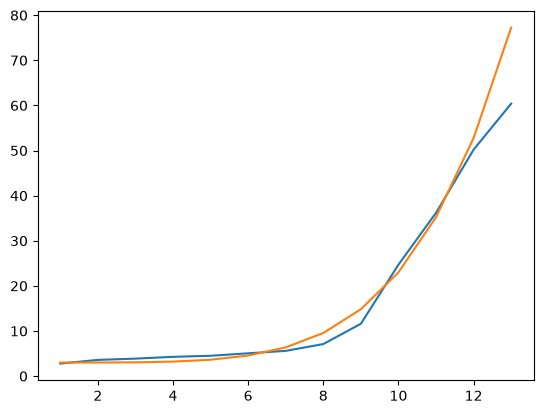

In [121]:
t = [2.77, 3.61, 3.9, 3.99, 4.64, 5.24] + [7.13, 10.1, 18.5, 27.9]
r = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

t = [2.77,3.59,3.87,4.27,4.5,5.05,5.59,7.1,11.6,24.7,36.2,50.2,60.4]
r = np.arange(1,14)
plt.plot(r,t)

C = 2e-4
offset = 3
data = C * r**5 + offset
plt.plot(r,data)

In [120]:
%%timeit
x = hiepy.randn((12,12,12,12,12,12), fixed_rank=13)
hiepy.ele_mul(x,x).rank()

60.4 ms ± 1.1 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [50]:
x = torch.arange(24,dtype=torch.double).reshape(2,3,4)
x = hiepy.to_htt(x,{"atol":1e-12})
print(x.full())
v = torch.arange(3)
xs = hiepy.ele_mode_mul(x,v,1)
xs.full()
torch.set_printoptions(threshold=0, sci_mode=False, precision=0)
print(xs.full())

tensor([[[-0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])
tensor([[[ 0,  0,  0,  0],
         [ 4,  5,  6,  7],
         [16, 18, 20, 22]],

        [[ 0,  0,  0,  0],
         [16, 17, 18, 19],
         [40, 42, 44, 46]]])


In [53]:
a = {"atol": 1e-2, "max_rank":5}
b = dict(**a)
a["atol"] = 10
b

{'atol': 0.01, 'max_rank': 5}

In [29]:
hiepy.ele_mode_mul(x,v,1).full()

tensor([[[3., 3., 3.],
         [4., 4., 4.],
         [5., 5., 5.]],

        [[3., 3., 3.],
         [4., 4., 4.],
         [5., 5., 5.]],

        [[3., 3., 3.],
         [4., 4., 4.],
         [5., 5., 5.]]])

In [36]:
norm_test = hiepy.contract(x_ht,x_ht)**0.5
norm_test

tensor(844.7868)

In [37]:
x_ht_o = x_ht.orthog()
norm_true = hiepy.contract(x_ht_o,x_ht_o)**0.5
print(f"{(norm_test - norm_true):.5e}")

-2.27374e-13


torch.float64

In [12]:
hiepy.to_htt(true,{"atol":1e-12}).rank()

{(0, 1, 2, 3): 1, (0,): 8, (1,): 8, (2,): 8, (3,): 8, (0, 1): 64, (2, 3): 64}